## Exploring the Comment data

In [1]:
import pandas as pd

df = pd.read_parquet("data/AWS PTS Reviews/issues_parquet/output_1.parquet")

print(df.shape)
print(df.dtypes)
df.head()

(500000, 12)
REVIEW_ID                   int64
REVIEW_CYCLE_ID             int64
DISCIPLINE                    str
STATUS                        str
DUE_DT             datetime64[ns]
COMPLETE_DT        datetime64[ns]
ISSUE_NUM                   int64
ISSUE_TEXT                    str
IS_CLEARED_IND                str
CLEARED_DT         datetime64[ns]
PROJ_ID                     int64
SCOPE                         str
dtype: object


,REVIEW_ID,REVIEW_CYCLE_ID,DISCIPLINE,STATUS,DUE_DT,COMPLETE_DT,ISSUE_NUM,ISSUE_TEXT,IS_CLEARED_IND,CLEARED_DT,PROJ_ID,SCOPE
0,1142,266,LDR-Engineering Review,Closed,2001-09-10,2001-09-06 09:05:24,1,"On the site and grading plans, move the propos...",N,NaT,1279,41-0458 CDP/VAR (Process 3) to demolish two s...
1,1142,266,LDR-Engineering Review,Closed,2001-09-10,2001-09-06 09:05:24,2,"Prior to the issuance of any building permits,...",N,NaT,1279,41-0458 CDP/VAR (Process 3) to demolish two s...
2,2405,517,BDR-Structural,Assignment Pending,NaT,NaT,1,These structural comments are for the prelimin...,N,NaT,1371,* [9/10/01] PRELIMINARY REVIEW MEETING FOR...
3,2405,517,BDR-Structural,Assignment Pending,NaT,NaT,2,Exit enclosures must extend to the exterior of...,N,NaT,1371,* [9/10/01] PRELIMINARY REVIEW MEETING FOR...
4,2405,517,BDR-Structural,Assignment Pending,NaT,NaT,3,The two stairs enclosures are not one-half the...,N,NaT,1371,* [9/10/01] PRELIMINARY REVIEW MEETING FOR...


In [2]:
df['SCOPE'][2]

'*    [9/10/01]  PRELIMINARY REVIEW MEETING FOR 15 MULTI FAMILY CONDOMINIUMS IN FIVE STORIES OVER ONE LEVEL SUBTERANEAN PARKING GARAGE at 2830 4th Avenue in the Uptown Community Plan.  ***** August 30, 2001, 1:00-3:00 , Conference Rm 4D*****'

## Patterns in permit review comments (exploratory, preliminary)

**Goal.** DSD reviewers leave written comments on plans ("issues"). If many comments repeat, or fall into a few themes, those themes are candidates for fixes: clearer checklists, better guidance for applicants, or templates. This notebook asks two questions:

1. Do many *similar* comments show up for each type of permit?
2. Which themes show up most, and where do they concentrate (which review discipline, which permit type)?

**Data.** Review comments pulled from DSD's P2K system (`data/AWS PTS Reviews/issues_parquet/`, 33 chunks of one result set). **One row = one review comment.** Review-level and project-level columns (discipline, dates, project scope) repeat on every comment of that review.

**Read this first.**
- To keep things fast we load only the **first `N_FILES` chunks** (set at the top; currently 2 of 33), so everything here is a *partial, exploratory* view. Numbers will move when more chunks are added.
- The data is raw and unvalidated. Results are preliminary and are not official City or DSD findings.
- Example comments are verbatim reviewer text (phone numbers, emails, and names written right next to them are masked where we could detect them, but names can still slip through). Check the outputs before sharing this notebook outside the team.

**Methods (only two, on purpose).** (1) Exact and near-exact matching after cleaning up the text, which shows boilerplate. (2) TF-IDF plus KMeans clustering, which groups comments by similar wording.

In [3]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import silhouette_score
from sklearn.metrics.pairwise import cosine_similarity

# Find the repo root whether the notebook runs from the root or notebooks/
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA = ROOT / "data"
PARQUET_DIR = DATA / "AWS PTS Reviews" / "issues_parquet"

N_FILES = 2      # how many parquet chunks to load (33 exist); raise this for a fuller picture
MIN_YEAR = 2010  # keep review comments from this year on (see step 2 for why)
SEED = 0         # fixed so the clusters are reproducible
BLUE = "#2a78d6"

pd.set_option("display.max_colwidth", 110)
pd.set_option("display.width", 200)

## 1. Load and inspect

We load the first `N_FILES` parquet chunks (sorted by the number in the file name, so `output_2` comes before `output_10`), stack them, and drop rows that are exact duplicates.

In [4]:
files = sorted(PARQUET_DIR.glob("output_*.parquet"), key=lambda p: int(p.stem.split("_")[1]))
raw = pd.concat([pd.read_parquet(f) for f in files[:N_FILES]], ignore_index=True)
issues = raw.drop_duplicates().reset_index(drop=True)

print(f"Loaded {N_FILES} of {len(files)} files: {[f.name for f in files[:N_FILES]]}")
print(f"Rows: {len(raw):,} -> {len(issues):,} after dropping exact duplicates")

Loaded 2 of 33 files: ['output_1.parquet', 'output_2.parquet']
Rows: 1,000,000 -> 1,000,000 after dropping exact duplicates


Next, the shape, column types, and how much of each column is missing.

In [5]:
print("Shape:", issues.shape)
pd.DataFrame({"dtype": issues.dtypes.astype(str), "null_rate": issues.isna().mean().round(3)})

Shape: (1000000, 12)


,dtype,null_rate
REVIEW_ID,int64,0.000
REVIEW_CYCLE_ID,int64,0.000
DISCIPLINE,str,0.000
STATUS,str,0.000
DUE_DT,datetime64[ns],0.113
COMPLETE_DT,datetime64[ns],0.122
ISSUE_NUM,int64,0.000
ISSUE_TEXT,str,0.000
IS_CLEARED_IND,str,0.000
CLEARED_DT,datetime64[ns],0.620


**What this means.** The two files hold exactly 1,000,000 comments and none is an exact duplicate. Comment text, discipline, and project ID are essentially always filled in. The gaps come from reviews that never finished: `DUE_DT` is blank on 11% of rows and `COMPLETE_DT` on 12%, and `CLEARED_DT` is blank on 62% because most comments were never marked cleared (checked below). `SCOPE` is missing for only 100 projects.

Now the date range. Review dates go back a long way, so we need to know how far.

In [6]:
for col in ["DUE_DT", "COMPLETE_DT", "CLEARED_DT"]:
    print(f"{col}: {issues[col].min():%Y-%m-%d} to {issues[col].max():%Y-%m-%d}")

DUE_DT: 2001-07-20 to 2026-06-25
COMPLETE_DT: 2001-07-23 to 2026-06-10
CLEARED_DT: 2001-07-23 to 2026-05-29


**What this means.** The data covers about 25 years, from July 2001 to June 2026. Forms, codes, and review practices change over that long a span, so we check below whether the old comments look different from recent ones.

Some comments have no text, so there is nothing to analyze: we drop those. We also add a `year` column (the year the review was completed, or due if it was never completed) so we can look at trends and, later, filter out old data.

In [7]:
empty = issues["ISSUE_TEXT"].isna() | (issues["ISSUE_TEXT"].str.strip() == "")
print(f"Dropping {empty.sum():,} rows with null or blank ISSUE_TEXT ({empty.mean():.2%})")
issues = issues[~empty].copy()

issues["year"] = issues["COMPLETE_DT"].dt.year.fillna(issues["DUE_DT"].dt.year).astype("Int64")
print(f"Rows left: {len(issues):,} | rows with no year (no completion or due date): {issues['year'].isna().sum():,}")

Dropping 327 rows with null or blank ISSUE_TEXT (0.03%)


Rows left: 999,673 | rows with no year (no completion or due date): 112,373


Row counts per discipline (a discipline is a reviewing group, such as structural or drainage) and per year.

In [8]:
print(issues["DISCIPLINE"].nunique(), "disciplines. Top 15 by number of comments:")
issues["DISCIPLINE"].value_counts().head(15).to_frame("comments").assign(pct=lambda d: (d["comments"] / len(issues) * 100).round(1))

135 disciplines. Top 15 by number of comments:


,comments,pct
DISCIPLINE,,
BDR-Structural,320924,32.1
IAS-Combined Review,114082,11.4
LDR-Drainage & Grades,71177,7.1
BDR-Mechanical,64438,6.4
LDR-Planning Review,39824,4.0
LDR-Eng Building Review,36364,3.6
LDR-Engineering Review,33808,3.4
BDR-Electrical,27610,2.8
LDR-Zoning,22367,2.2


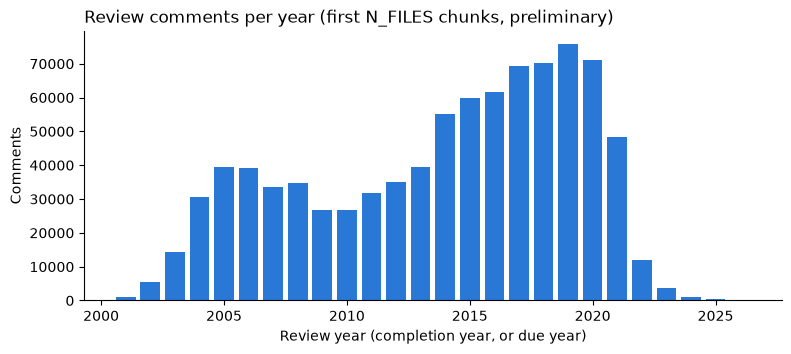

In [9]:
per_year = issues["year"].value_counts().sort_index()

fig, ax = plt.subplots(figsize=(9, 3.5))
ax.bar(per_year.index.astype(int), per_year.values, color=BLUE)
ax.set_xlabel("Review year (completion year, or due year)")
ax.set_ylabel("Comments")
ax.set_title("Review comments per year (first N_FILES chunks, preliminary)", loc="left")
ax.spines[["top", "right"]].set_visible(False)
plt.show()

**What this means.**
- **Discipline:** three groups write half of all comments: BDR-Structural (32%), IAS-Combined Review (11%), and LDR-Drainage & Grades (7%). There are 135 disciplines in total, so the rest is a long tail.
- **Year:** volume grows from 2004, sits around 30,000 to 40,000 comments a year until 2013, then jumps to 55,000 to 76,000 a year in 2014 to 2020 (peak 75,880 in 2019). It drops after 2021 (48,447 in 2021, 11,991 in 2022, under 4,000 after that). A likely reason is that newer projects are handled in another system, which is worth confirming with DSD.
- 112,373 comments (11%) have no year because their review has no completion or due date (all are cancelled or never-assigned reviews).

**Is `REVIEW_CYCLE_ID` a 1/2/3 cycle counter?** The description suggested it is a global ID, so we check: how many distinct values, how wide the range, and how many projects and reviews share one value.

In [10]:
cycle = issues.groupby("REVIEW_CYCLE_ID").agg(reviews=("REVIEW_ID", "nunique"), projects=("PROJ_ID", "nunique"))
per_project = issues.groupby("PROJ_ID")["REVIEW_CYCLE_ID"].nunique()

print(f"Distinct REVIEW_CYCLE_ID: {len(cycle):,} (values run from {issues['REVIEW_CYCLE_ID'].min():,} to {issues['REVIEW_CYCLE_ID'].max():,})")
print(f"Projects per cycle id:   max {cycle['projects'].max()}")
print(f"Reviews per cycle id:    median {cycle['reviews'].median():.0f}, max {cycle['reviews'].max()}")
print(f"Cycle ids per project:   median {per_project.median():.0f}, max {per_project.max()}")

Distinct REVIEW_CYCLE_ID: 180,332 (values run from 15 to 2,677,474)
Projects per cycle id:   max 1
Reviews per cycle id:    median 1, max 8
Cycle ids per project:   median 1, max 73


**What this means.** `REVIEW_CYCLE_ID` is a global ID, not a 1/2/3 counter: there are 180,332 distinct values running from 15 to about 2.7 million. Each belongs to exactly one project and usually to one review (median 1, at most 8). A project has a median of 1 cycle ID but up to 73. So the number of review rounds per project is not given directly; we would have to derive it, for example by ordering each project's cycle IDs (or review dates) within a discipline.

**How reliable is the "cleared" flag?** `IS_CLEARED_IND` says whether a comment was resolved. We check how often it is "Y", whether it agrees with `CLEARED_DT`, and whether it changes with year or review status.

Flag is 'Y' exactly when CLEARED_DT is filled: True
Share of all comments marked cleared: 38%


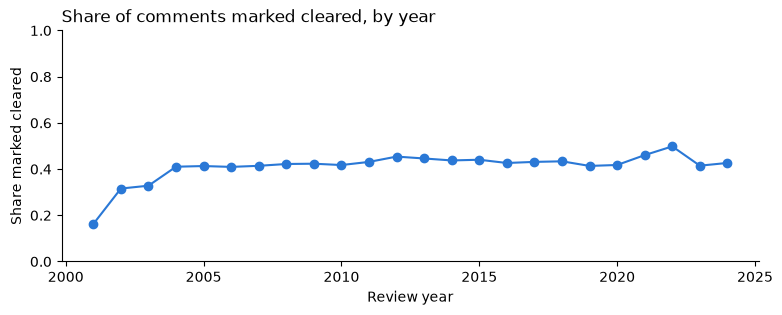

,comments,share_cleared
STATUS,,
Assigned,6,0.00
Assignment Pending,27691,0.01
Cancelled,96968,0.03
Closed,873205,0.43
Completed,1756,0.55
Started,47,0.38


In [11]:
cleared = (issues["IS_CLEARED_IND"] == "Y").rename("cleared")
print("Flag is 'Y' exactly when CLEARED_DT is filled:", bool((cleared == issues["CLEARED_DT"].notna()).all()))
print(f"Share of all comments marked cleared: {cleared.mean():.0%}")

by_year = cleared.groupby(issues["year"]).agg(["size", "mean"])
by_year = by_year[by_year["size"] >= 1000]   # ignore years with very few comments
by_status = cleared.groupby(issues["STATUS"]).agg(comments="size", share_cleared="mean").round(2)

fig, ax = plt.subplots(figsize=(9, 3))
ax.plot(by_year.index.astype(int), by_year["mean"], marker="o", color=BLUE)
ax.set_ylim(0, 1)
ax.set_xlabel("Review year")
ax.set_ylabel("Share marked cleared")
ax.set_title("Share of comments marked cleared, by year", loc="left")
ax.spines[["top", "right"]].set_visible(False)
plt.show()
by_status

**What this means.** The "cleared" flag is **not a reliable record of resolution**, and it does not get better in recent years.
- It is "Y" exactly when `CLEARED_DT` is filled, so the two columns carry the same information.
- Only 38% of all comments are marked cleared. The share is about 40% to 50% in every year from 2004 on (lower in 2001 to 2003, about 16% to 33%).
- Even in reviews with status Closed, only 43% of comments are marked cleared, and in Cancelled reviews 3%. So more than half of the comments in finished reviews were never marked cleared, which means "N" mostly means "nobody clicked it", not "still open". We should not use this flag as an outcome.

## 2. Permit type from `SCOPE`

`SCOPE` is the project description typed in by staff. It repeats on every comment of a project, so we work with one row per project (`PROJ_ID`) and merge the result back. We first look at a random sample and at the most common starting words.

In [12]:
scopes = issues.drop_duplicates("PROJ_ID")[["PROJ_ID", "SCOPE"]].reset_index(drop=True)
print(f"{len(scopes):,} projects, {scopes['SCOPE'].isna().sum()} with no SCOPE\n")

print("Random sample of SCOPE values:")
for s in scopes["SCOPE"].dropna().sample(20, random_state=SEED):
    print(" -", " ".join(s.split())[:115])

89,641 projects, 100 with no SCOPE

Random sample of SCOPE values:
 - BLACK MOUNTAIN RANCH Electrical permit for roof mounted photo-voltaic system at new single family residence. RS-1-1
 - j.o. 41-0268 Community Plan Amendment, Rezone, Site Development Permit, Tentative Map (Process 5) to rezone a 2.58 
 - DOWNTOWN. Building, electrical, mechanical, and plumbing permits for remodel to extg restaurant. Work to include se
 - CLAIREMONT MESA JO#42-5413 (PROCESS 3) Tentative Map to create two parcels from one existing 0.27 acre site at 4301
 - MISSION VALLEY. Right of way permit for sidewalk, curb, utility connections and roadway work.
 - MID CITY..Proposed Tenant Improvement for an (e) retail space, scope of work is to add a dimising wall to make area
 - OTAY MESA: Building, Electrical & Plumbing Permits for the permitting of (1) existing non-permitted state approved 
 - SAN YSIDRO Building Permit for new 1,786 sq ft warehouse on site with two existing buildings. SYIO-CSR-2, Geo 53, C
 - 

In [13]:
first_words = scopes["SCOPE"].dropna().str.split().str[:2].str.join(" ").str.upper()
print("Most common first two words:")
first_words.value_counts().head(12).to_frame("projects")

Most common first two words:


,projects
SCOPE,
CONSTRUCTION CHANGE,3376
LA JOLLA,2758
GREATER NORTH,2035
SOUTHEASTERN SAN,1357
MIRA MESA,1357
SCOPE CHANGE,1286
PACIFIC BEACH,1184
LA JOLLA:,1032
CLAIREMONT MESA,1004


The formats are all over the place. Some start with a project number and permit codes (`41-0458 CDP/VAR (Process 3) ...`), but most start with a community name (`MIRA MESA: Combination Building Permit for ...`), and others have no permit words at all (`Interior tenant improvement ...`). How much of this did the earlier regex catch?

In [14]:
old_pattern = r"^\s*[\d-]+\s+([A-Z/&\s]+?)\s*\(Process"
old_hits = scopes["SCOPE"].str.extract(old_pattern)[0].notna().sum()
print(f"Earlier regex matches {old_hits} of {len(scopes):,} projects ({old_hits / len(scopes):.3%})")

Earlier regex matches 4 of 89,641 projects (0.004%)


**New approach: ordered keyword rules.** Instead of one pattern anchored to the start, we look for permit-type words in the first 200 characters (the type is stated up front; later text often mentions other permits in passing). Rules are tried in priority order and the first match wins:

1. Explicit words first (`construction change`, `deferred`), then the permit names written out (`Combination Building Permit`, `Building Permit`), then other types.
2. **Discretionary permit codes** (CDP, SDP, CUP, ...) count only when a **Process level** is stated, because that marks a real discretionary project. Otherwise a code is usually just a reference inside a building permit (`... Zone: RS-1-4 / SDP#40-0508`). A code is also used when nothing else matched.
3. Anything still unmatched is labelled `Unknown` (never dropped).

The process level (`Process 1` to `Process 5`, written as digits or words) is read separately. The rules were tuned by repeatedly looking at what stayed `Unknown` and at wrong matches (for example the word "row" in "row homes").

In [15]:
HEAD = 200  # characters of SCOPE to search
text = scopes["SCOPE"].fillna("").str.replace(r"\s+", " ", regex=True).str.strip().str[:HEAD]

# Process level: "Process 3", "PROCESS TWO", "Process No. 4"
words = {"one": "1", "two": "2", "three": "3", "four": "4", "five": "5"}
scopes["process_level"] = (
    text.str.extract(r"(?i)\bprocess\s*(?:no\.?\s*)?(1|2|3|4|5|one|two|three|four|five)\b")[0]
    .str.lower().replace(words)
)

# Discretionary permit codes. Spelled-out names become codes, then we take the first code in the text.
spelled_out = {"coastal development permit": "CDP", "site development permit": "SDP",
               "neighborhood development permit": "NDP", "neighborhood use permit": "NUP",
               "conditional use permit": "CUP", "planned development permit": "PDP", "variance": "VAR"}
code_names = {"CDP": "Coastal Development Permit (CDP)", "SDP": "Site Development Permit (SDP)",
              "NDP": "Neighborhood Development Permit (NDP)", "NUP": "Neighborhood Use Permit (NUP)",
              "CUP": "Conditional Use Permit (CUP)", "PDP": "Planned Development Permit (PDP)",
              "VAR": "Variance (VAR)"}
with_codes = text
for name, abbreviation in spelled_out.items():
    with_codes = with_codes.str.replace(name, abbreviation, case=False, regex=False)
permit_code = with_codes.str.extract(r"\b(CDP|SDP|NDP|NUP|CUP|PDP|VAR)\b")[0].map(code_names)  # codes must be uppercase

# Keyword rules, highest priority first. (?i) = ignore case; (?-i:...) = case-sensitive piece.
RULES = [
    ("Construction Change", r"(?i)construction chang|const\.? chg|^CC\b|\bdelta\b"),
    ("Deferred Submittal", r"(?i)deferred"),
    ("Combination Building Permit", r"(?i)combination|\bcombo\b"),
    ("Building Permit", r"(?i)\b(?:building|bldg)\b.{0,60}\bpermits?\b"),
    ("Map / Rezone / Plan Amendment", r"(?i)(?-i:\bTPM?\b)|tentative map|parcel map|map waiver|lot line|lot consolidation|dedication|final map|rezone|re-zone|community plan amend|\bCPA\b"),
    ("Right-of-Way / Street Work", r"(?i)right[- ]of[- ]way|(?-i:\bR-?O-?W\b|\bPROW\b)"),
    ("Zone History Letter", r"(?i)zone history|\bZHL\b"),
    ("Zoning Affidavit", r"(?i)zoning affidavit"),
    ("Public Project / Improvements", r"(?i)public project|public improvement|\bPPA\b|\bWBS\b|\bCIP\b|improvement plans"),
    ("Easement / Street Vacation", r"(?i)easement|vacation"),
    ("Right-of-Way / Street Work", r"(?i)\btrench\w*|\bexcavat\w*|\bdig\b|street asphalt"),
    ("Demolition", r"(?i)demolition|\bdemo\b"),
    ("Grading", r"(?i)\bgrading\b|as[- ]graded"),
    ("Tenant Improvement", r"(?i)tenant impr|\bT\.?\s?I\.?\b"),
    ("Sign", r"(?i)\bsigns?\b|signage"),
    ("Solar / Photovoltaic", r"(?i)solar|photovoltaic|\bPV\b"),
    ("Pool / Spa", r"(?i)\bpool\b|\bspa\b"),
    ("Companion / Junior Unit", r"(?i)companion unit|junior unit|\bJADU\b|\bADU\b"),
    ("Fire Systems", r"(?i)fire (?:alarm|sprinkler|service|suppression|permit)|sprinkler|suppression|hydrant"),
    ("Wireless / Telecom", r"(?i)wireless|\bWCF\b|telecom|cell site|antenna"),
    ("Electrical / Plumbing / Mechanical", r"(?i)\b(?:electrical|plumbing|mechanical|elect|mech)\b.{0,15}\b(?:permits?|only)\b"),
    ("Preliminary / Multi-Discipline Review", r"(?i)pre-?lim\w*(?:\s+planning)?(?:\s+review)?|pre-?application|multi[- ]?disc\w*|single disc\w*|screen check|\bSCR\b|substantial conformance"),
    ("Other building work", r"(?i)\b(?:addition|remodel\w*|residence|dwelling|single family|foundation|repair|conversion|improvements?|sfr|sfd|sfu|sdu|duplex|garage|patio|deck|retaining wall|ret walls?|fence|roof|windows?|interior|convert\w*|construct\w*|install\w*|alteration|upgrade|master plan|new)\b"),
]

scopes["permit_type"] = "Unknown"
for label, pattern in reversed(RULES):          # lowest priority first, so higher-priority rules overwrite it
    scopes.loc[text.str.contains(pattern, regex=True), "permit_type"] = label

# A discretionary code wins when a Process level is stated, or when nothing else matched
explicit = scopes["permit_type"].isin(["Construction Change", "Deferred Submittal"])
use_code = permit_code.notna() & ~explicit & (scopes["process_level"].notna() | (scopes["permit_type"] == "Unknown"))
scopes.loc[use_code, "permit_type"] = permit_code[use_code]

issues = issues.merge(scopes[["PROJ_ID", "permit_type", "process_level"]], on="PROJ_ID", how="left")

How well did it work? Share of comments and projects left as `Unknown`, the most common permit types, and examples of what failed.

Unknown: 1.3% of comments, 1.6% of projects
Process level found on 14.1% of comments

                                       comments   pct
permit_type                                          
Building Permit                          305561  30.6
Combination Building Permit              264240  26.4
Right-of-Way / Street Work                56891   5.7
Map / Rezone / Plan Amendment             42500   4.3
Other building work                       39515   4.0
Coastal Development Permit (CDP)          36887   3.7
Site Development Permit (SDP)             35057   3.5
Construction Change                       30928   3.1
Preliminary / Multi-Discipline Review     28304   2.8
Planned Development Permit (PDP)          19970   2.0 



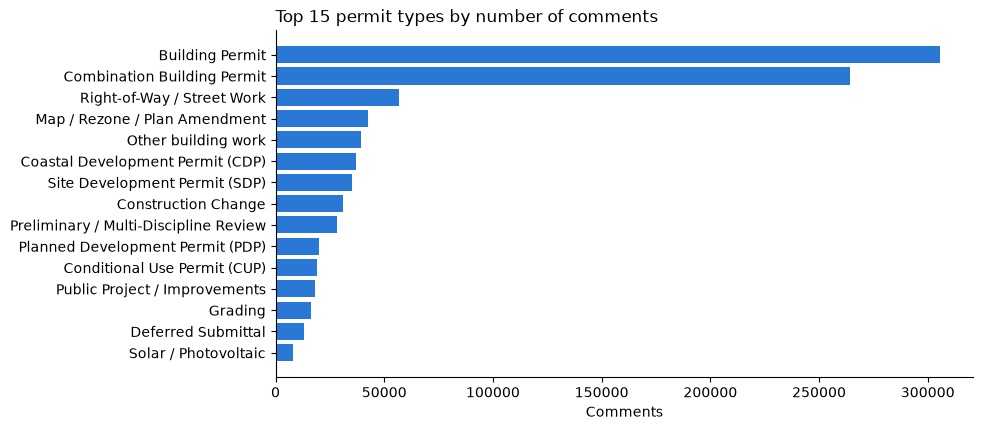

Examples left Unknown:
 - Alternate Materials and Methods submittal for Project #526261, Approval #1847720. Requesting to use alternate 
 - partitions, ceiling, electrical, and ductwork for an existing law firm
 - ENCANTO NEIGHBORHOODS: Certificate of Compliance for Parcels 1-7 as shown on ROS 21962.
 - Various alternatives to permit retrained detainees in three hold rooms to be in a non-fire resistive bldg
 - OCEAN BEACH:*****LIGHTGIG****** Place (1) 432 PFP Cabinet, remove and restore sidewalk, remove tree stump in p
 - LA JOLLA: Propose to remove and replace concrete driveway apron with pavers. Remove and replace damaged sidewa
 - Site lighting for private streets and parking for (11) building multi-family project. Connect lighting to (11)
 - CX to PTS 698065 Approval 2583697 Move running line to avoid power vault, storm drain inlet, power & comm line
 - Request for Altenate Methods and Material project associate with 621575. Use of ABS/PVC in lieu of cast iron.
 - Temporary Seating

In [16]:
by_type = issues["permit_type"].value_counts().to_frame("comments").assign(pct=lambda d: (d["comments"] / len(issues) * 100).round(1))
print(f"Unknown: {by_type.loc['Unknown', 'pct']}% of comments, {(scopes['permit_type'] == 'Unknown').mean():.1%} of projects")
print(f"Process level found on {issues['process_level'].notna().mean():.1%} of comments\n")

top15 = by_type.drop("Unknown").head(15)
print(top15.head(10).to_string(), "\n")
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.barh(top15.index[::-1], top15["comments"][::-1], color=BLUE)
ax.set_xlabel("Comments")
ax.set_title("Top 15 permit types by number of comments", loc="left")
ax.spines[["top", "right"]].set_visible(False)
plt.show()

print("Examples left Unknown:")
for s in scopes.loc[scopes["permit_type"] == "Unknown", "SCOPE"].dropna().sample(12, random_state=SEED):
    print(" -", " ".join(s.split())[:110])

In [17]:
issues.drop_duplicates("PROJ_ID")["process_level"].value_counts(dropna=False).to_frame("projects").T

process_level,NaN,3,2,4,5,1
projects,81981,3227,2014,1402,657,360


**What this means.**
- The earlier regex matches only 4 of 89,641 projects: it only fits the old `41-0458 CDP/VAR (Process 3)` style.
- The new rules leave **1.3% of comments** (1.6% of projects) as `Unknown`. The leftovers are mostly one-offs, such as alternate-materials requests, certificates of compliance, or scopes with no permit words at all.
- **Building Permit** and **Combination Building Permit** together make up more than half of all comments. Right-of-way work, maps/rezones, and the discretionary permits (CDP, SDP, PDP, CUP) follow.
- Process levels appear on about 14% of comments (about 7,700 projects, mostly Process 3). They go with discretionary projects, which are reviewed in a more formal way.
- **Limits:** the type is a best guess from free text, each project gets exactly one type, `Other building work` (about 4% of comments) is a catch-all, and "Building" vs. "Combination" follows the words staff typed, not an official permit code.

**Do older comments look different?** The data starts in 2001. Before using all of it, we compare the mix of permit types across periods (share of comments, %). Rows with no year are left out of this table.

In [18]:
era = pd.cut(issues["year"].astype(float), [2000, 2009, 2013, 2021, 2100], labels=["2001-09", "2010-13", "2014-21", "2022+"])
top_types = issues["permit_type"].value_counts().index[:8]
type_group = issues["permit_type"].where(issues["permit_type"].isin(top_types), "all others")
pd.crosstab(era, type_group, normalize="index").mul(100).round(0).astype(int)

permit_type,Building Permit,Coastal Development Permit (CDP),Combination Building Permit,Construction Change,Map / Rezone / Plan Amendment,Other building work,Right-of-Way / Street Work,Site Development Permit (SDP),all others
year,,,,,,,,,
2001-09,26,5,23,1,7,10,2,5,20
2010-13,38,3,29,2,3,3,3,2,17
2014-21,35,3,30,4,3,2,8,2,14
2022+,12,7,15,22,1,1,9,3,31


**What this means.** Permit mix is similar for 2010 to 2013 and 2014 to 2021, but 2001 to 2009 looks different: 10% of comments fall in the catch-all `Other building work` (2% to 3% later), map/rezone is 7% (3% later), and right-of-way and construction changes are rare. Part of this is probably older scopes being written differently, so they are harder to classify. 2022 and later is thin and dominated by construction changes (22%). We therefore keep **2010 onward**. This is a judgment call: change `MIN_YEAR` at the top to test it.

In [19]:
recent = issues[issues["year"] >= MIN_YEAR].copy()
print(f"Keeping review years >= {MIN_YEAR}: {len(recent):,} of {len(issues):,} comments ({len(recent) / len(issues):.0%})")
print(f"Dropped: {(issues['year'] < MIN_YEAR).sum():,} older comments and {issues['year'].isna().sum():,} with no year")
print("Statuses of the no-year rows:", issues.loc[issues["year"].isna(), "STATUS"].value_counts().to_dict())

Keeping review years >= 2010: 662,125 of 999,673 comments (66%)
Dropped: 225,175 older comments and 112,373 with no year
Statuses of the no-year rows: {'Cancelled': 84695, 'Assignment Pending': 27678}


**What this means.** We keep two thirds of the comments (662,125). The 112,373 comments with no year come from cancelled (84,695) and never-assigned (27,678) reviews. They cannot be placed in time, so they are left out here. That loses some comments from cancelled reviews, which is a small bias to keep in mind.

## 3. Method 1: exact and near-exact repeats

To find comments that are "the same" even when small details differ, we normalize the text: lowercase, turn sheet or page references into the word `sheet`, remove all numbers, remove punctuation, and collapse extra spaces. For example, `See sheet A-2.1 and A-3 for the detail` becomes `see sheet for the detail`. Then we count how often each normalized comment occurs.

We also keep a cleaned copy of the original text (phone numbers, emails, and names written next to them masked) to show as readable examples.

In [20]:
sheet_ref = r"\b(?:sheets?|pages?|pgs?)\b[\s.#:]*(?:no\.?)?\s*[a-z]{0,2}[-.\s]?\d[\w.\-/]*(?:\s*(?:,|and|&|thru|through)\s*[a-z]{0,2}[-.\s]?\d[\w.\-/]*)*"
# phone numbers and emails, plus a capitalized name written right before them ("Call Ron (619) ...")
contact = r"(?:\b[A-Z][a-z]+(?:\s[A-Z][a-z]+)?\s+(?:at\s+)?)?(?:\(?\b\d{3}\)?[-.\s]\d{3}[-.\s]\d{4}\b|\b[\w.+-]+@[\w-]+\.[\w.]+\b)"

norm = recent["ISSUE_TEXT"].str.lower()
norm = norm.str.replace(sheet_ref, "sheet", regex=True)   # "sheets 3, 4 & 5" -> "sheet"
norm = norm.str.replace(r"\d+", " ", regex=True)          # numbers
norm = norm.str.replace(r"[^a-z\s]", " ", regex=True)     # punctuation and symbols
recent["norm"] = norm.str.replace(r"\s+", " ", regex=True).str.strip()
recent["example"] = recent["ISSUE_TEXT"].str.replace(r"\s+", " ", regex=True).str.replace(contact, "[contact]", regex=True).str.strip()

blank = recent["norm"] == ""
print(f"Dropping {blank.sum()} comments that were only numbers or symbols")
recent = recent[~blank].copy()
print(f"{len(recent):,} comments, {recent['norm'].nunique():,} distinct after normalizing, {recent['ISSUE_TEXT'].nunique():,} distinct before")

Dropping 36 comments that were only numbers or symbols


662,089 comments, 350,357 distinct after normalizing, 381,312 distinct before


In [21]:
def unique_comments(frame):
    """One row per distinct normalized comment: how often it occurs and one readable example."""
    out = frame.groupby("norm").agg(count=("norm", "size"), example=("example", "first")).reset_index()
    out["pct"] = (out["count"] / len(frame) * 100).round(2)
    return out


def top_comments(frame, n=10):
    out = unique_comments(frame).sort_values("count", ascending=False).head(n)[["count", "pct", "example"]]
    out["example"] = out["example"].str[:110]   # keep the tables narrow
    return out


print("Top 20 most common comments overall")
top_comments(recent, 20)

Top 20 most common comments overall


,count,pct,example
142771,3924,0.59,Please indicate here if any changes have been made to the plans that are not a result of corrections from ...
332799,3272,0.49,This list does not necessarily include all errors and omissions. Plans require correction as indicated by ...
99138,2392,0.36,It is the responsibility of architect or engineer of record to ensure that all requirements of the latest ...
20205,2052,0.31,"All Issue Boxes without check marks, requirements still need to be corrected or addressed. Please Indicate..."
335283,1701,0.26,"To facilitate rechecking, provide an itemized written response to the issues noted in this plan review she..."
138092,1614,0.24,"Please come back for a ""Walk-in"" over the counter re- check when all corrections have been provided, note ..."
74178,1545,0.23,"For useful and detailed information concerning the plan review, permit process, and number of plans and do..."
333007,1485,0.22,This plan can be rechecked over the counter (OTC) by any electrical plan reviewer.
135830,1406,0.21,"Please be advised, supplemental plan review fees may be charged where insufficient progress is made in res..."
99144,1337,0.20,It is the responsibility of the architect or engineer of record to assure that all requirements of the lat...


**What this means.** The most common comments are **not about any one project**. They are standard text that reviewers paste into reviews:
- form instructions ("Please indicate here if any changes have been made to the plans..." appears 3,924 times; "This list does not necessarily include all errors and omissions..." 3,272 times),
- how to recheck or resubmit (itemized written response, walk-in recheck, recheck by appointment, "can be rechecked over the counter by any electrical plan reviewer"),
- notices (the architect or engineer of record is responsible for code compliance, supplemental review fees, historic-resource review steps, links to DSD web pages).

All 20 are of this kind. Each one still covers under 1% of comments, because the same text exists in many slightly different versions.

The same view inside each of the six biggest disciplines: what does each group of reviewers repeat most?

In [22]:
for discipline in recent["DISCIPLINE"].value_counts().index[:6]:
    sub = recent[recent["DISCIPLINE"] == discipline]
    print(f"\n=== {discipline} ({len(sub):,} comments)")
    print(top_comments(sub, 10).to_string(index=False, header=["count", "pct", "example"]))


=== BDR-Structural (226,062 comments)
count  pct                                                                                                        example
 1677 0.74 To facilitate rechecking, provide an itemized written response to the issues noted in this plan review sheet. 
 1547 0.68 Please indicate here if any changes have been made to the plans that are not a result of corrections from this
 1534 0.68 For useful and detailed information concerning the plan review, permit process, and number of plans and docume
 1396 0.62 Please be advised, supplemental plan review fees may be charged where insufficient progress is made in respond
 1326 0.59 It is the responsibility of the architect or engineer of record to assure that all requirements of the latest 
 1303 0.58 Projects initially reviewed over-the-counter on the 3rd floor can be rechecked with any structural reviewer at
 1208 0.53 Recheck of plans will be performed by appointment. For a recheck appointment, please call [conta

**What this means.** Each discipline has its own set of standard comments, and they come in two flavors.
- **Process notices.** In BDR-Structural and BDR-Mechanical the top comments are recheck instructions and responsibility notices. In Mechanical, the top three alone are about 15% of the discipline's comments (5.0%, 5.0%, 4.7%).
- **Plan content that is often missing.** In IAS-Combined Review the repeated requests are specific: who pays the water and sewer fees, where the backflow assembly goes, make/model/capacity of the water heater, output of the heating unit, clearance around toilets. In LDR-Eng Building Review: earthwork quantities and impervious-area tables, and a standard storm-water note. These are natural candidates for an applicant checklist, since applicants are being asked for the same things again and again.
- LDR-Drainage & Grades has more variety; its top comments are about redlines and written responses.

And inside the four biggest permit types (leaving out `Unknown`).

In [23]:
for permit in recent["permit_type"].value_counts().drop("Unknown").index[:4]:
    sub = recent[recent["permit_type"] == permit]
    print(f"\n=== {permit} ({len(sub):,} comments)")
    print(top_comments(sub, 5).to_string(index=False, header=["count", "pct", "example"]))


=== Building Permit (228,839 comments)
count  pct                                                                                                        example
 2774 1.21 Please indicate here if any changes have been made to the plans that are not a result of corrections from this
 2358 1.03 This list does not necessarily include all errors and omissions. Plans require correction as indicated by comm
 2014 0.88 It is the responsibility of architect or engineer of record to ensure that all requirements of the latest adop
 1026 0.45 Projects initially reviewed over-the-counter on the 3rd floor can be rechecked with any structural reviewer at
  900 0.39 Provide an itemized written response to the issues noted in this plan review sheet. The written response shall

=== Combination Building Permit (196,458 comments)
count  pct                                                                                                        example
 1529 0.78 All Issue Boxes without check marks, requir

count  pct                                                                                                        example
  216 0.78 Please indicate here if any changes have been made to the plans that are not a result of corrections from this
  216 0.78 This list does not necessarily include all errors and omissions. Plans require correction as indicated by comm
  172 0.62 Recheck of plans will be performed by appointment. For a recheck appointment, please call [contact]. Please ha
  148 0.53 It is the responsibility of architect or engineer of record to ensure that all requirements of the latest adop
  141 0.51 Provide an itemized written response to the issues noted in this plan review sheet. The written response shall


**What this means.** Building Permit, Combination Building Permit, and Construction Change reviews share the same standard text (the "changes made?" form, "list does not include all errors", the architect-of-record notice). Combination permits also carry the historic-resource notices. Right-of-Way / Street Work is different: its top comments are short and free-form ("refer to the redlined plan set") and each covers only about 0.3% of comments, so this type has much less boilerplate.

**How much of everything is boilerplate?** We rank the distinct normalized comments by how often they occur and ask what share of all comments the top N cover.

Comments whose normalized text appears more than once: 53.1%


Comments whose normalized text appears 10+ times:      38.2%
Distinct comments needed to cover half of all comments: 29,420 of 350,357



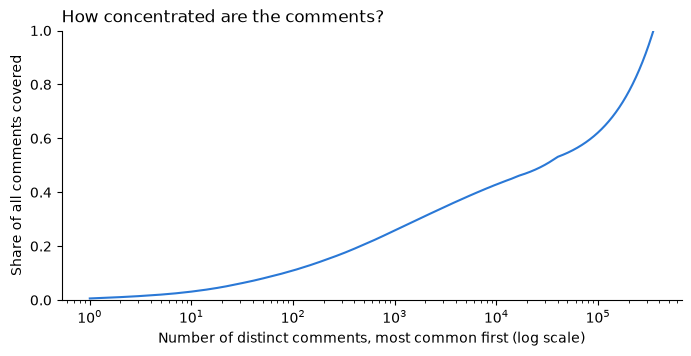

,top_N_distinct_comments,share_of_all_comments
0,10,3.1%
1,100,11.0%
2,1000,25.8%
3,10000,42.9%


In [24]:
counts = recent["norm"].value_counts()
covered = counts.cumsum() / len(recent)

coverage = pd.DataFrame({"top_N_distinct_comments": [10, 100, 1000, 10000]})
coverage["share_of_all_comments"] = [f"{covered.iloc[n - 1]:.1%}" for n in coverage["top_N_distinct_comments"]]
print(f"Comments whose normalized text appears more than once: {(recent['norm'].map(counts) > 1).mean():.1%}")
print(f"Comments whose normalized text appears 10+ times:      {(recent['norm'].map(counts) >= 10).mean():.1%}")
print(f"Distinct comments needed to cover half of all comments: {(covered < 0.5).sum() + 1:,} of {len(counts):,}\n")

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(np.arange(1, len(covered) + 1), covered.values, color=BLUE)
ax.set_xscale("log")
ax.set_xlabel("Number of distinct comments, most common first (log scale)")
ax.set_ylabel("Share of all comments covered")
ax.set_title("How concentrated are the comments?", loc="left")
ax.set_ylim(0, 1)
ax.spines[["top", "right"]].set_visible(False)
plt.show()
coverage

**What this means.**
- **53%** of comments have a normalized text that appears more than once, and **38%** appear 10 or more times. The other 47% are one-offs.
- No handful of comments dominates: the top 10 cover only 3.1%, the top 100 cover 11%, the top 1,000 cover 26%, and the top 10,000 cover 43%.
- Half of all comments come from just 29,420 of the 350,357 distinct comments (about 8%).

So repetition is widespread but spread over many variants. Our normalization only fixes case, numbers, and punctuation. Rewordings and typos still count as different comments, so real repetition is higher than this, which is why we cluster next.

## 4. Method 2: TF-IDF and KMeans clustering

Exact matching misses comments that say the same thing in different words. TF-IDF turns each comment into numbers that capture which words it uses (down-weighting very common words), and KMeans then groups comments with similar wording.

To keep it fast, we cluster the **distinct normalized comments** (about 350k instead of 660k rows) and **weight each one by how many times it occurs**, so a comment repeated 3,000 times counts 3,000 times. The vocabulary is the 5,000 most useful words and word pairs (stop words like "the" are ignored; a term must appear in at least 5 distinct comments).

In [25]:
def fit_tfidf(uniq):
    vec = TfidfVectorizer(stop_words="english", min_df=5, max_features=5000, ngram_range=(1, 2))
    return vec, vec.fit_transform(uniq["norm"])


def fit_kmeans(X, counts, k, n_init=3):
    """KMeans weighted by comment counts. Clusters are renumbered so 0 is the biggest."""
    km = KMeans(n_clusters=k, n_init=n_init, random_state=SEED).fit(X, sample_weight=counts)
    size = pd.Series(counts).groupby(km.labels_).sum().sort_values(ascending=False)
    new_id = {old: new for new, old in enumerate(size.index)}
    return pd.Series(km.labels_).map(new_id).values, km.cluster_centers_[size.index]


def show_clusters(uniq, vec, X, labels, centers, n_examples=3):
    """Print size, top terms, and the comments closest to each cluster centre. Returns a summary table."""
    terms = np.array(vec.get_feature_names_out())
    rows = []
    for c in range(len(centers)):
        idx = np.where(labels == c)[0]
        top_terms = ", ".join(terms[np.argsort(-centers[c])[:7]])
        share = uniq["count"].values[idx].sum() / uniq["count"].sum()
        rows.append({"cluster": c, "pct_of_comments": round(share * 100, 1), "distinct_comments": len(idx), "top_terms": top_terms})
        print(f"\n[{c}] {share:.1%} of comments, {len(idx):,} distinct | {top_terms}")
        for i in idx[np.argsort(-(X[idx] @ centers[c]))[:n_examples]]:
            print("     -", uniq["example"][i][:140])
    return pd.DataFrame(rows).set_index("cluster")


uniq = unique_comments(recent)
vec, X = fit_tfidf(uniq)
counts = uniq["count"].values
print("Distinct comments:", X.shape[0], "| vocabulary size:", X.shape[1])

Distinct comments: 350357 | vocabulary size: 5000


**Choosing k (the number of clusters).** We try a few values and look at the silhouette score on a sample (it measures how well separated the clusters are, from -1 to 1) and at how lopsided the clusters are.

In [26]:
trials = []
for k in [10, 20, 30, 40]:
    labels_k, _ = fit_kmeans(X, counts, k, n_init=1)
    share = pd.Series(counts).groupby(labels_k).sum() / counts.sum()
    trials.append({"k": k,
                   "silhouette": round(silhouette_score(X, labels_k, sample_size=5000, random_state=SEED), 3),
                   "largest_cluster_share": round(share.max(), 2),
                   "clusters_under_1pct": int((share < 0.01).sum())})
pd.DataFrame(trials).set_index("k")

,silhouette,largest_cluster_share,clusters_under_1pct
k,,,
10,-0.001,0.52,0
20,-0.000,0.43,5
30,-0.001,0.35,10
40,0.001,0.32,19


**What this means.** Silhouette is about 0 for every k (-0.001 to 0.001). That is normal for short, sparse text with one huge generic group, and it means the clusters are **not sharply separated**, so it cannot pick k for us. More clusters shrink the biggest one (52% at k=10, 43% at k=20, 35% at k=30, 32% at k=40) but create many tiny ones (0, 5, 10, and 19 clusters under 1%). We use **k = 20**: themes are readable and the clusters are not too tiny.

In [27]:
K = 20
labels, centers = fit_kmeans(X, counts, K)
summary = show_clusters(uniq, vec, X, labels, centers)


[0] 43.3% of comments, 194,239 distinct | plans, provide, project, plan, review, proposed, existing
     - Provide detail for uprights on plans.
     - Provide dry pendant detail on plans. [contact]
     - Provide combo permit # on plans, 1470716

[1] 12.3% of comments, 41,798 distinct | shall, cbc, inches, sec, minimum, section, feet
     - Sheet A1.4/Details 1 & 2 - Restrooms: a. Lavatory shall be 18 inches minimum from face of a side wall or partition to centerline (CBC, Sec. 
     - Show that the spiral stairway complies with the following requirements [Sec. R311.7.9.1]: - Minimum clear width of 26 inches at and below th
     - No wine or distiled spirits shall be sold in containers ofless than 375 milliliters.

[2] 9.4% of comments, 52,582 distinct | sheet, plan, provide, revise, sheet provide, proposed, plans
     - Sheet P 2.02: What are the sybols in hexagonals with "S" refering to?
     - Please have the exhbit be 8.5" x 11" sheet.
     - Sheet 8: There are 4 bore pits.

[3] 

**What this means.** The cluster numbers and percentages below are for this run (`N_FILES = 2`, `MIN_YEAR = 2010`) and will change with more data. Clusters are numbered by size (0 is the biggest).
- **A big generic group (cluster 0, 43%).** Short, project-specific requests like "Provide detail for uprights on plans". No shared theme beyond "provide X on the plans".
- **Standard recheck and response text (clusters 9, 13, 14, 16, 17, 18, 19).** Only 2,559 distinct comments, but they make up **7.9% of all comments**: "this list does not include all errors", "recheck over the counter by any plan reviewer", the "changes made?" box, "note the page number in the margin", "recheck by appointment", "itemized written response", the architect-of-record notice. This is the clearest boilerplate.
- **Other standard notices (clusters 6, 7, 10, 12).** Links to web guides (3.2%), "additional comments may follow" (2.5%), special-inspections notes (1.8%), historic-resource review steps (1.7%).
- **Code requirements and notes to add (clusters 1 and 3).** Text full of code citations ("shall", "CBC", "inches", "section", 12%) and "add the following note to the plans" (7%, only about 4,900 distinct comments).
- **Topic themes (clusters 4, 5, 8, 11, 15).** Water meter and sewer (3.4%), roof and framing (3.2%), storm water (1.8%), accessible parking (1.7%), professional stamp or signature (1.0%).
- **Sheet-specific comments (cluster 2, 9%).** "Sheet P 2.02: what are the symbols...", which are about one drawing and are not boilerplate.

**Within the biggest disciplines.** Different reviewers write about different things, so a global clustering can hide themes inside one discipline. We repeat the same steps separately for the three biggest disciplines (8 clusters each, one example per cluster).

In [28]:
for discipline in recent["DISCIPLINE"].value_counts().index[:3]:
    sub = recent[recent["DISCIPLINE"] == discipline]
    uniq_d = unique_comments(sub)
    vec_d, X_d = fit_tfidf(uniq_d)
    labels_d, centers_d = fit_kmeans(X_d, uniq_d["count"].values, 8)
    print(f"\n######## {discipline}: {len(sub):,} comments, {len(uniq_d):,} distinct")
    show_clusters(uniq_d, vec_d, X_d, labels_d, centers_d, n_examples=1)


######## BDR-Structural: 226,062 comments, 109,125 distinct

[0] 70.5% of comments, 104,221 distinct | sheet, provide, shall, plans, plan, cbc, building
     - Plans as submitted are incomplete and a meaningful plan review can not be accomplished. Provide a full set of demolition plans, floor plans,

[1] 6.4% of comments, 819 distinct | note plans, make following, following note, note, shall, plans, cfc
     - Make the following note on the plans "Exits, exit signs, fire alarm panels, hose cabinets, fire extinguisher locations, and standpipe connec

[2] 5.2% of comments, 455 distinct | plan review, development services, development, services, review, plan, supplemental
     - 1-Plans must be submitted for recheck. Please submit revised plans and all associated documents electronically through Open DSD. 2-Please be

[3] 4.1% of comments, 739 distinct | changes, list, plans, responsibility, result, satisfied, latest
     - It is the responsibility of the architect or engineer of record 


######## IAS-Combined Review: 76,037 comments, 23,703 distinct

[0] 57.0% of comments, 18,272 distinct | plans, provide, floor, plan, shall, heating, recheck
     - Recheck Over-The-Counter- [contact] to schedule an appointment for an over-the-counter recheck on the third floor. Check in with the third f

[1] 15.8% of comments, 3,864 distinct | water, meter, water meter, card, backflow, data, meter data
     - Water Meter Data Card Please sign the Water Meter Data Card.

[2] 10.2% of comments, 454 distinct | add following, following note, note plans, add, note, following, gallons
     - Add the following note to the plans: "Provide kitchen faucets with a maximum flow of 1.8 gallons per minute (GPM)."

[3] 4.5% of comments, 273 distinct | issue located, answer issue, sheet answer, margin requirement, requirement sheet, number margin, answer
     - Or you may come back for a "Walk-in" over the counter re- check when all corrections have been provided, note the page number in the margin 


######## LDR-Drainage & Grades: 51,321 comments, 37,095 distinct

[0] 36.0% of comments, 13,712 distinct | provide, plans, emra, review, note, project, approval
     - REJECTED PROJECT: This project is submitted in conjunction with the on-site Grading per PTS 692170 per Substantial Conformance Review PTS 64

[1] 28.4% of comments, 12,853 distinct | sheet, proposed, plan, existing, revise, remove, legend
     - Sheet 4: 3.83

[2] 11.2% of comments, 4,862 distinct | curb, sheet provide, provide, sheet, street, property, table
     - Page 1 - Please provide the Appoval No. 1548660.

[3] 11.1% of comments, 1,736 distinct | comments, additional, address, additional comments, plans, review, address comments
     - Drainage and Grades General Comments: Please contact me directly at [contact] if you have any questions/concerns. Please address all comment

[4] 6.7% of comments, 2,480 distinct | number, title, block, title block, sheets, sheet, project
     - Sheet 10 - title block: please move

**What this means.** Splitting by discipline shows themes that the global clusters blur.
- **BDR-Structural:** 70% is a generic group. About 30% sits in standard-text clusters: recheck and response instructions (about 16%), plus notes to add to the plans (fire-code notes 6%, off-site fabricator 4%, special inspections 4%).
- **IAS-Combined Review:** water meter and sewer fees (about 20%), energy and plumbing notes ("add the following note": faucet flow, high-efficacy lighting, low-flush toilets, about 15%), and recheck instructions (about 8%). These are code-driven and look like checklist or template material.
- **LDR-Drainage & Grades:** mostly project-specific (28% start with a sheet reference, 36% is a generic group) and only about 3% is boilerplate.

**Where do the themes concentrate?** We attach each comment's cluster, then compare each cluster's make-up with the overall make-up. The number in each cell is a *lift*: 1.0 means the discipline (or permit type) appears in that cluster exactly as often as it does overall, 2.0 means twice as often, 0.5 half as often. Red is over-represented, blue is under-represented.

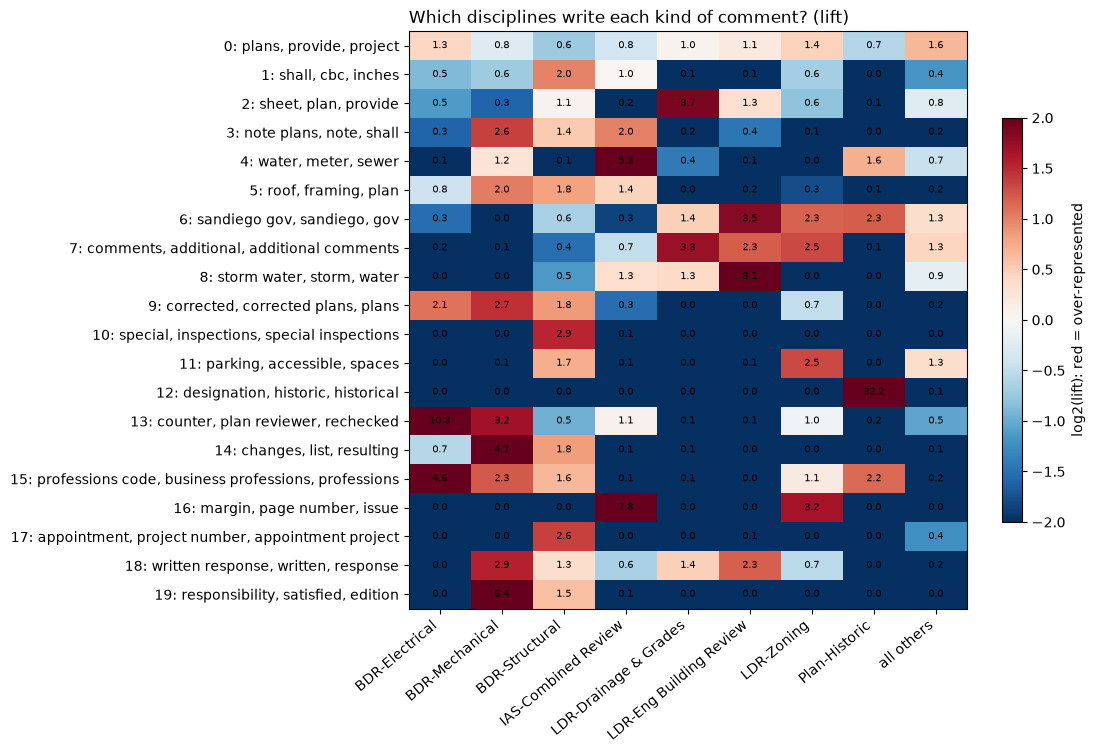

Strongest concentrations (cluster, group), cells with at least 200 comments:
                                 lift  comments
cluster DISCIPLINE                             
12      Plan-Historic            32.2     10885
13      BDR-Electrical           10.3      3005
8       LDR-Eng Building Review   8.1      4518
16      IAS-Combined Review       7.8      5731
19      BDR-Mechanical            6.4      2355
4       IAS-Combined Review       5.3     13989
14      BDR-Mechanical            4.7      2216
15      BDR-Electrical            4.6       880
2       LDR-Drainage & Grades     3.7     17711
6       LDR-Eng Building Review   3.5      3395


In [29]:
recent["cluster"] = recent["norm"].map(pd.Series(labels, index=uniq["norm"]))
cluster_names = [f"{c}: " + ", ".join(summary.loc[c, "top_terms"].split(", ")[:3]) for c in summary.index]


def lift_heatmap(column, top_n, title):
    """Cluster vs. group. Lift = share of the cluster in this group / share of all comments in this group."""
    biggest = recent[column].value_counts().index[:top_n]
    grouped = recent[column].where(recent[column].isin(biggest), "all others")
    lift = pd.crosstab(recent["cluster"], grouped, normalize="index") / grouped.value_counts(normalize=True)
    fig, ax = plt.subplots(figsize=(9, 7.5))
    image = ax.imshow(np.log2(lift.clip(lower=0.25)), cmap="RdBu_r", vmin=-2, vmax=2, aspect="auto")   # clip: lift 0 has no log
    ax.set_xticks(range(lift.shape[1]), lift.columns, rotation=40, ha="right")
    ax.set_yticks(range(lift.shape[0]), cluster_names)
    for i in range(lift.shape[0]):
        for j in range(lift.shape[1]):
            ax.text(j, i, f"{lift.iat[i, j]:.1f}", ha="center", va="center", fontsize=7)
    ax.set_title(title, loc="left")
    fig.colorbar(image, label="log2(lift): red = over-represented", shrink=0.7)
    plt.show()

    cells = lift.stack().rename("lift").to_frame()
    cells["comments"] = pd.crosstab(recent["cluster"], grouped).stack()
    print("Strongest concentrations (cluster, group), cells with at least 200 comments:")
    print(cells[cells["comments"] >= 200].sort_values("lift", ascending=False).head(10).round(1).to_string())


lift_heatmap("DISCIPLINE", 8, "Which disciplines write each kind of comment? (lift)")

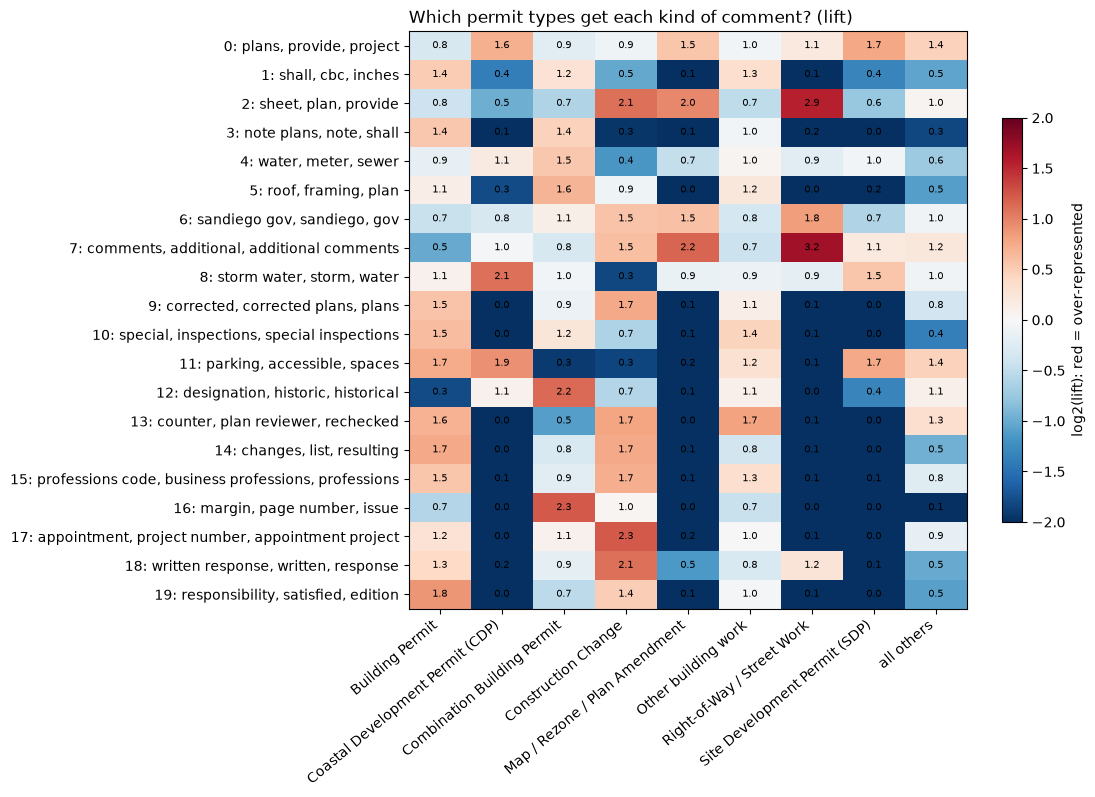

Strongest concentrations (cluster, group), cells with at least 200 comments:
                                          lift  comments
cluster permit_type                                     
7       Right-of-Way / Street Work         3.2      3600
2       Right-of-Way / Street Work         2.9     12553
16      Combination Building Permit        2.3      4429
17      Construction Change                2.3       617
7       Map / Rezone / Plan Amendment      2.2      1055
12      Combination Building Permit        2.2      7192
8       Coastal Development Permit (CDP)   2.1       700
18      Construction Change                2.1       480
2       Construction Change                2.1      5548
        Map / Rezone / Plan Amendment      2.0      3512


In [30]:
lift_heatmap("permit_type", 8, "Which permit types get each kind of comment? (lift)")

**What this means.** The standard text is **tied to particular disciplines and permit types**. Strongest concentrations (lift, with comment counts in the table above):
- **By discipline:** the historic-review notices are almost entirely Plan-Historic (cluster 12, lift 32); "can be rechecked over the counter by any electrical plan reviewer" is Electrical (cluster 13, lift 10); storm-water text is LDR-Eng Building Review (cluster 8, lift 8); the "note the page number in the margin" and water meter and sewer text are IAS-Combined Review (clusters 16 and 4, lift 8 and 5); the architect-of-record notice and the "changes made?" box are Mechanical (clusters 19 and 14, lift 6 and 5); sheet-specific comments are Drainage & Grades (cluster 2, lift 4).
- **By permit type:** Right-of-Way / Street Work and Map / Rezone reviews rarely use the standard recheck text (lift around 0.1 in most boilerplate clusters). They lean on sheet-specific comments (cluster 2) and "additional comments may follow" (cluster 7). Construction Change reviews carry more of the recheck and written-response text (clusters 17 and 18, lift about 2). Combination Building Permits get the historic notices (cluster 12, lift 2.2).

In plain terms: boilerplate is mostly a habit of particular review groups, so any fix would be discipline by discipline. **Caveat:** discipline and permit type are tangled together (some disciplines mostly review some permit types), and permit type is our own guess from free text.

**Nearest neighbours.** For three sample comments (picked at random from comments that occur at least 20 times) we list the five most similar comments by cosine similarity (1.0 = identical word weights). This shows how much wording variation sits behind one idea.

In [31]:
for i in uniq[uniq["count"] >= 20].sample(3, random_state=SEED).index:
    sims = cosine_similarity(X[i], X).ravel()
    print(f"\nCOMMENT (occurs {uniq.at[i, 'count']} times): {uniq.at[i, 'example'][:150]}")
    for j in sims.argsort()[::-1][1:6]:     # position 0 is the comment itself
        print(f"   {sims[j]:.2f}  {uniq.at[j, 'example'][:130]}")


COMMENT (occurs 44 times): Indicate project construction cost.
   0.95  Indicate cost of construction.
   0.92  Indicate project approximate cost.
   0.92  Indicate project cost.
   0.92  Indicate project costruction cost.
   0.89  What is the project construction cost?

COMMENT (occurs 24 times): Surfaces regulated in CBC Sec. 709A.3/CRC R327.9.3 # 2, 3 shall be constructed with exterior fire-retardant-treated wood or approved noncombustible ma
   0.98  DECK Surfaces regulated in CBC Sec. 709A.3/CRC R327.9.3 # 2, 3 shall be constructed with exterior fire-retardant-treated wood or a
   0.98  Plan 6 Deck Surfaces regulated in CBC Sec. 709A.3/CRC R327.9.3 # 2, 3 shall be constructed with exterior Fire -Retardant-treated w
   0.76  Decking: Materials- The surfaces regulated in Section 704A.4.1.1 shall be constructed with heavy timber decking per CBC Section 60
   0.76  The surfaces regulated in Section 704A.4.1.1 shall be constructed with heavy timber decking per CBC Section 602.4, or ex

**What this means.** The same idea shows up in many wordings that exact matching cannot join. "Indicate project construction cost" (44 times) has near-twins at 0.89 to 0.95 similarity: "Indicate cost of construction", "Indicate project cost", a version with a typo, and "What is the project construction cost?". The deck-surfaces code comment differs only by a prefix ("DECK", "Plan 6 Deck") at 0.98. A fixed template for these would remove a lot of variation, and similarity search is a cheap way to find such families.

## 5. Summary (exploratory and preliminary)

**What we did.** Loaded 2 of 33 chunks (1,000,000 comments), derived permit type from `SCOPE` (1.3% left `Unknown`), kept review years 2010 and later (662,125 comments, 350,357 distinct after normalizing), then looked at exact repeats and at TF-IDF + KMeans clusters (k = 20).

**What we learned.**
1. **Lots of comments are standard text.** 53% of comments repeat, 38% appear 10 or more times, and all 20 most common comments are boilerplate. Half of all comments come from about 8% of the distinct ones (29,420).
2. **Themes.**
   - Recheck and response text (about 8% of comments, only 2,559 distinct comments).
   - Other standard notices (web links, "additional comments may follow", special inspections, historic review, about 9%).
   - Code citations and "add the following note to the plans" (about 19%).
   - Topic clusters: water and sewer, roofs and framing, storm water, accessible parking.
   - Sheet-specific, project-by-project comments (about 9%).
   - A broad "provide X on the plans" group (43%) with no shared theme.
3. **The text is tied to disciplines and permit types.** For example, historic notices sit in Plan-Historic, the "recheck by any electrical plan reviewer" line in Electrical, and storm-water text in LDR-Eng Building Review. Right-of-way and map/rezone reviews are mostly free-form.
4. **Ideas to explore (hypotheses, not findings).** Recheck and response instructions could be delivered by the portal instead of repeated as comments. Repeated requests for specific plan content (water and sewer fee payer, water heater data, earthwork and impervious-area tables, energy notes) could become checklist items. Many near-duplicate wordings could be replaced by one standard comment.

**Limitations.**
- **Partial data:** 2 of 33 chunks, so cluster numbers and percentages will change with more data.
- **Old and missing data:** we kept 2010 onward; 112,373 comments with no year (cancelled or never-assigned reviews) are left out; volume falls sharply after 2021, possibly because of a system change (to confirm with DSD).
- **`IS_CLEARED_IND` is unreliable:** only 43% of comments in Closed reviews are marked cleared, so we cannot study which comments were resolved. `REVIEW_CYCLE_ID` is a global ID, so review rounds per project are not given directly.
- **Noisy methods:** permit type is guessed from free text; silhouette is about 0, so clusters are soft; the biggest cluster is a catch-all; normalization misses rewordings and typos; cluster themes were named by eye.
- The data is raw and unvalidated, and nothing here is an official City or DSD finding.

**Suggested next steps.**
- Load more chunks (raise `N_FILES`). The two chunks use about 0.6 GB in memory, so all 33 would need batching or sampling.
- Sentence embeddings with HDBSCAN to group rewordings without choosing k.
- Repeated comments across cycles on the same project: derive the cycle order, then check which comments come back.
- Comment themes versus review time and number of cycles, by joining to the Reviews extract.
- Ask DSD which standard texts come from templates, what changed after 2021, and how P2K projects link to current records.